# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [2]:
# Add code here 🔧
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("cleaned_airbnb_data_6.csv")
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,bedrooms_was_missing,has_reviews
0,2992450,https://www.airbnb.com/rooms/2992450,20260616211424,2026-06-16,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,https://a0.muscache.com/pictures/44627226/0e72...,4621559,https://www.airbnb.com/users/show/4621559,...,4.56,3.22,3.67,1,1,0,0,0.06,False,True
1,3820211,https://www.airbnb.com/rooms/3820211,20260616211424,2026-06-16,city scrape,Restored Precinct in Center Sq. w/Parking,Step into the charming and comfy 1BR/1BA apart...,https://a0.muscache.com/pictures/prohost-api/H...,19648678,https://www.airbnb.com/users/show/19648678,...,4.81,4.82,4.78,7,7,0,0,2.20,False,True
2,5651579,https://www.airbnb.com/rooms/5651579,20260616211424,2026-06-16,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",https://a0.muscache.com/pictures/b3fc42f3-6e5e...,29288920,https://www.airbnb.com/users/show/29288920,...,4.87,4.75,4.63,2,1,1,0,3.00,True,True
3,6623339,https://www.airbnb.com/rooms/6623339,20260616211424,2026-06-16,city scrape,Center Sq. Loft in Converted Precinct w/ Parking,Step into the charming and comfy 1BR/1BA apart...,https://a0.muscache.com/pictures/prohost-api/H...,19648678,https://www.airbnb.com/users/show/19648678,...,4.70,4.80,4.72,7,7,0,0,2.47,False,True
4,9501054,https://www.airbnb.com/rooms/9501054,20260616211424,2026-06-16,city scrape,Spacious suite with full bath by Capital Center,Great location within walking distance to the ...,https://a0.muscache.com/pictures/45153167-d704...,29288920,https://www.airbnb.com/users/show/29288920,...,4.87,4.77,4.68,2,1,1,0,3.71,True,True


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

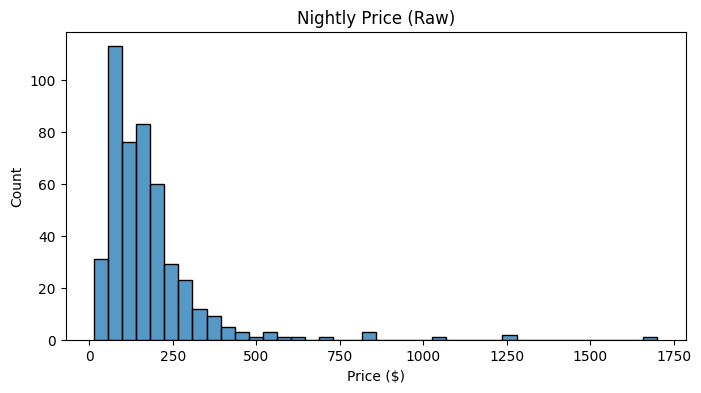

Skewness before: 4.6


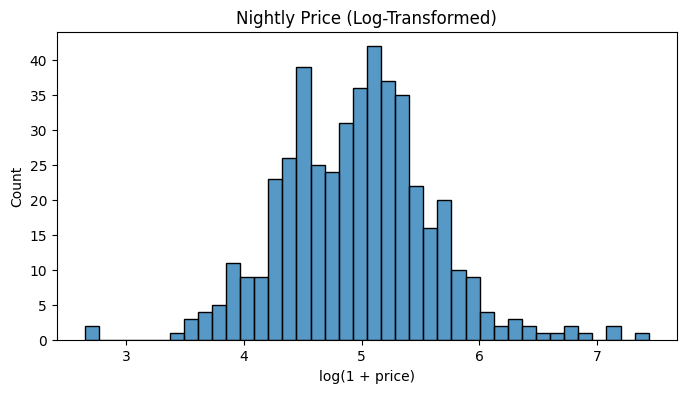

Skewness after: 0.21


In [3]:
# Add code here 🔧
price = df["price"].dropna()

plt.figure(figsize=(8, 4))
sns.histplot(price, bins=40)
plt.title("Nightly Price (Raw)")
plt.xlabel("Price ($)")
plt.show()

print("Skewness before:", round(price.skew(), 2))

df["log_price"] = np.log1p(df["price"])

plt.figure(figsize=(8, 4))
sns.histplot(df["log_price"].dropna(), bins=40)
plt.title("Nightly Price (Log-Transformed)")
plt.xlabel("log(1 + price)")
plt.show()

print("Skewness after:", round(df["log_price"].skew(), 2))

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I examined price, the nightly rate for each listing in Albany. I picked it because I believe it is the most important metric to inspect for hosts and marketing managers. It also had a very wide range.

2. I applied a log transformation. The original histogram was right-skewed, with majority of listings under $250, and a few very expensive ones. Skewness was 4.6, very high, and the mean was well above the median. A log transformation worked here because it shrank the large values more than it did smaller ones, which helped pull the outliers tighter. I did log1p over regular log because it handles zero values. The skewness became 0.21.

3. This transition made the data more usable because models function more smoothly and accurately when data is symmetrical. The raw data was skewed and had outliers which could overly influence a models outputs. Graphically the original histogram was clustered on the left which makes it hard to visualize and different between all of those listings. That is crucial because those are the listings that need to be compored against each other.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [5]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-Max scale
avail = df["availability_365"]
df["availability_365_minmax"] = (avail - avail.min()) / (avail.max() - avail.min())

# Z-score scale
price = df["price"]
df["price_zscore"] = (price - price.mean()) / price.std()

df[["availability_365", "availability_365_minmax", "price", "price_zscore"]].describe().round(2)

,availability_365,availability_365_minmax,price,price_zscore
count,490.00,490.00,458.00,458.00
mean,242.89,0.67,177.13,0.00
std,116.60,0.32,157.35,1.00
min,0.00,0.00,13.18,-1.04
25%,164.50,0.45,90.00,-0.55
50%,284.50,0.78,145.67,-0.20
75%,347.75,0.95,209.62,0.21
max,365.00,1.00,1701.00,9.68



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I scaled availability 365 and price. I used min-max scaling on availability which scaled it to a 0-1 range. I used z-score standardization on price, which expressed each price as the number of standard deviations away from the average.

2. Scaled values are more useful when theyy need to be compared or combined. Before price had higher nomical values and would dominate because of that. Putting both on comparable scales lets each contribute fairly.

3. Data scientists and pricing teams would benefit because they could feed the scaled price and availability data into models and get better outputs to make decisions. Those models could inform them of listings that are mispriced compared to similar ones.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [6]:
# Add code here 🔧
bins = [-1, 10, 50, float("inf")]
labels = ["Low", "Medium", "High"]

df["review_volume"] = pd.cut(df["number_of_reviews"], bins=bins, labels=labels)

print(df["review_volume"].value_counts().reindex(labels))

df.groupby("review_volume", observed=True)["number_of_reviews"].agg(["count", "min", "max"])

review_volume
Low       220
Medium    115
High      155
Name: count, dtype: int64


,count,min,max
review_volume,,,
Low,220,0,10
Medium,115,11,50
High,155,51,996


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped the number of reviews column and I utilized three categories.

2. Someone would prefer the grouped view because it is much easier to scan, filter, and explain when you don't want to deal with exact counts. It makes comparisons easier and simpler. It also doesn't accentuate small differences

3. Marketing teams would be helped with this sort of data. For example high-volume listings could be used as featured customer favorite properties.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [7]:
# Add code here 🔧
df["price_per_guest"] = df["price"] / df["accommodates"]

df["is_long_term_stay"] = (df["minimum_nights"] >= 30).astype(int)

print(df[["price", "accommodates", "price_per_guest", "minimum_nights", "is_long_term_stay"]].head(10))
print()
print(df["price_per_guest"].describe().round(2))
print()
print(df["is_long_term_stay"].value_counts())

    price  accommodates  price_per_guest  minimum_nights  is_long_term_stay
0   80.43             4        20.107500            28.0                  0
1  211.00             3        70.333333             1.0                  0
2   97.00             2        48.500000             1.0                  0
3  160.00             2        80.000000             1.0                  0
4   86.00             2        43.000000             1.0                  0
5   58.00             1        58.000000             1.0                  0
6  277.31            10        27.731000             1.0                  0
7   62.87             1        62.870000            15.0                  0
8   64.00             1        64.000000             5.0                  0
9  313.00             6        52.166667             2.0                  0

count    458.00
mean      58.26
std       28.79
min       13.18
25%       38.33
50%       52.10
75%       73.34
max      316.75
Name: price_per_guest, dtype: float

### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created price per guest and is long term stay. Price per guest helps give a more accurate true cost rather than the sheer undivided number. Long term stay helps flag for rentals that are 30 nights or more which would help with monthly rental listings.

2. Hosts would use them. They could use price per guest to ensure their pricing is in line with comparable listings.

3. A host that notices it's price per guest is well above their peers can evaluate the reasoning and then decide whether to adjust it or keep it if they feel the premium is justifiable.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [8]:
# Add code here 🔧
room_dummies = pd.get_dummies(df["room_type"], prefix="room", dtype=int)

df = pd.concat([df, room_dummies], axis=1)

print(df["room_type"].value_counts())
print()
print(df[["room_type"] + list(room_dummies.columns)].head(8))
print()
print("Each row has exactly one 1:", (room_dummies.sum(axis=1) == 1).all())

room_type
Entire home/apt    345
Private room       135
Hotel room           9
Shared room          1
Name: count, dtype: int64

         room_type  room_Entire home/apt  room_Hotel room  room_Private room  \
0  Entire home/apt                     1                0                  0   
1  Entire home/apt                     1                0                  0   
2  Entire home/apt                     1                0                  0   
3  Entire home/apt                     1                0                  0   
4     Private room                     0                0                  1   
5     Private room                     0                0                  1   
6  Entire home/apt                     1                0                  0   
7     Private room                     0                0                  1   

   room_Shared room  
0                 0  
1                 0  
2                 0  
3                 0  
4                 0  
5                 

### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded room type. I chose it because it is a driving factor in pricing and demand. it is also stored as a text so a model can't use it until it's converted to numbers.

2. I used one-hot encoding with pd.get-dummies which created a 0/1 column per room type. I chose this over ordinal encoding because the room types have no natural order and ranking them could tell a model one is better or preferable and that is not the case.

3. This could help a pricing model by allowing it to learn how much room type affects price on its own. In my data, a private room and an entire house would serve very different customers and price ranges. This transformations would give the model the ability to read a new variable it couldn't before.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [9]:
# export csv here 🔧
df.to_csv("cleaned_airbnb_data_7.csv", index=False)

## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. I found the price per gust transformation most important. This is something that would help as a consumer because I know the struggle of finding a listing where an entire group of my friends can agree on a price for a rental.

2. To a host, the price per guest would be most useful. It shows whether a listing is fairly priced compared to similar ones and that is one the easiest and straightforwards comparisons that can be done.

3. I would first handle the remaining missing values so all of the data can go into a model. I would build a pricing tool that predicts a fair nightly rate using all metrics of data about the listing that we have such as room type, location, size, amount of guests etc. This would allow me to have the most accurate pricing with the least hastle.

4. this helped me build python skills for auditing, especially creating new variables from one I already had. By dividing price by the number of guests, I made price per guest, a metric that wasn't in the dataset but allowed me to measure and compare listings against each other. Auditors do things like this with performance ratios and metrics to find outliers and spot anomalies.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"